# AI-Image Detector v3.1 — CLIP features + multi-source data (self-contained)

**Run top to bottom. Everything is downloaded or generated by the notebook itself — no manual dataset download, no paid generators.**

### Why v3 exists (the honest conclusion)
* **CIFAKE (and any CNN trained from scratch on one dataset) cannot be fixed by tuning.** CIFAKE is 32×32 pictures of 10 object classes. A 1000-px cartoon-style portrait, shrunk to 32×32, looks like nothing the network has ever seen. The same happens with GenImage when a small CNN is trained from scratch: it memorises the *artifacts of the generators in the dataset* and breaks on a new generator, a new style, resizing or JPEG.
* **What works better in the research literature** (Ojha et al., *UnivFD*, CVPR 2023): take a big **frozen pretrained CLIP vision model**, extract an embedding from a native-resolution crop, and train only a **small linear classifier** on top. It generalises to unseen generators far better than a trained-from-scratch CNN, trains in minutes and needs far less data.
* v3 adds: several data sources, **free local image generation** (SD-Turbo on the GPU) to cover styles like 3D-cartoon, **JPEG/resize augmentation** (so "file format" can't be a shortcut), **leave-one-source-out testing** (the number that actually predicts how it behaves on new images), calibrated probabilities and an **UNCERTAIN band**.

### Limits you should know
No detector is reliable on every image. Stylised/cartoon/3D images are the hardest, because real hand-made art also looks "synthetic". This notebook measures that and tells you when it is unsure instead of pretending. **To fix failures like your fireworks image, put similar images in `my_data/fake/` (and look-alike real ones in `my_data/real/`) and re-run** — the notebook trains on them.

Recommended hardware: free Colab GPU (T4). On CPU it switches to a smaller backbone and is slow.

## 1. Install

In [1]:
%pip install -q --upgrade transformers datasets diffusers accelerate scikit-learn scipy pillow tqdm matplotlib joblib huggingface_hub

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and configuration

In [2]:
import os, io, json, math, random, hashlib, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm
ImageFile.LOAD_TRUNCATED_IMAGES = True
Image.MAX_IMAGE_PIXELS = 200_000_000
warnings.filterwarnings("ignore")

import torch
import torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
HAS_GPU = torch.cuda.is_available()
device = torch.device("cuda" if HAS_GPU else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if HAS_GPU else "(CPU: will be slow; use Colab GPU if you can)")

# ---------------- settings you may change ----------------
BACKBONE       = "openai/clip-vit-large-patch14" if HAS_GPU else "openai/clip-vit-base-patch16"
N_PER_CLASS    = 3000 if HAS_GPU else 600     # images per class, per online dataset
N_LOCAL_FAKES  = 1500 if HAS_GPU else 0       # images generated locally with SD-Turbo (GPU only)
MY_DATA_REPEAT = 8                            # your own images are re-used with different augmentation
BATCH          = 64 if HAS_GPU else 16
CROP           = 224
BAND_FAKE, BAND_REAL = 0.80, 0.20             # P(AI) >= 0.80 -> LIKELY AI, <= 0.20 -> LIKELY REAL, else UNCERTAIN
# ----------------------------------------------------------

ROOT = Path.cwd()
CACHE, MODELS, RESULTS = ROOT/"cache_v3", ROOT/"models_v3", ROOT/"results_v3"
GENERATED = ROOT/"generated_fakes"
MY_DATA = ROOT/"my_data"
for d in (CACHE, MODELS, RESULTS, GENERATED, MY_DATA/"real", MY_DATA/"fake", ROOT/"test_images"):
    d.mkdir(parents=True, exist_ok=True)
TAG = BACKBONE.split("/")[-1]
EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
print("Backbone:", BACKBONE, "| working folder:", ROOT)

Device: cuda NVIDIA GeForce RTX 3050 Laptop GPU
Backbone: openai/clip-vit-large-patch14 | working folder: c:\Users\Tankala Bhaskar teja\ISC_PROJECT-KOMAL


## 3. Load the CLIP backbone (frozen — never trained)
The embedding is the 768-d (L/14) or 512-d (B/16) CLIP image feature. Only a logistic-regression head on top is trained.

In [3]:
from transformers import CLIPModel
clip = CLIPModel.from_pretrained(BACKBONE, torch_dtype=torch.float16 if HAS_GPU else torch.float32).to(device).eval()
for p in clip.parameters(): p.requires_grad_(False)
MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(1, 3, 1, 1)
STD  = torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(1, 3, 1, 1)

@torch.no_grad()
def embed(batch_u8):
    '''batch_u8: numpy uint8 (B, CROP, CROP, 3) -> L2-normalised float32 embeddings (B, D).'''
    x = torch.from_numpy(batch_u8).permute(0, 3, 1, 2).float().div(255.0)
    x = ((x - MEAN) / STD).to(device=device, dtype=clip.dtype)
    pooled = clip.vision_model(pixel_values=x).pooler_output
    f = clip.visual_projection(pooled).float()
    return F.normalize(f, dim=-1).cpu().numpy()

print("Embedding dimension:", embed(np.zeros((1, CROP, CROP, 3), np.uint8)).shape[1])

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Embedding dimension: 768


## 4. Image preprocessing and *degradation* augmentation
* The model sees a **native-resolution 224×224 crop** (no shrink-to-32). Tiny images are up-scaled; large ones are cropped.
* During training, **both classes** are randomly down-sized and JPEG re-compressed. This stops the classifier from using "PNG vs JPEG" or "resolution" as a shortcut, and makes it tolerant to social-media / SnapEdit-style re-saving.

In [4]:
RESAMPLE = [Image.Resampling.BILINEAR, Image.Resampling.BICUBIC, Image.Resampling.LANCZOS]

def degrade(img):
    w, h = img.size
    if min(w, h) > 1536:                              # speed: huge photos -> ~1024 short side
        s = 1024 / min(w, h); img = img.resize((round(w*s), round(h*s)), Image.Resampling.LANCZOS); w, h = img.size
    if random.random() < 0.5 and min(w, h) > 300:     # random down-size
        target = random.randint(256, min(min(w, h), 1024))
        s = target / min(w, h)
        img = img.resize((max(1, round(w*s)), max(1, round(h*s))), random.choice(RESAMPLE))
    if random.random() < 0.7:                         # random JPEG re-compression
        buf = io.BytesIO(); img.save(buf, "JPEG", quality=random.randint(55, 95)); buf.seek(0)
        img = Image.open(buf).convert("RGB")
    return img

def ensure_min_size(img):
    w, h = img.size
    if min(w, h) < CROP:
        s = CROP / min(w, h)
        img = img.resize((max(CROP, math.ceil(w*s)), max(CROP, math.ceil(h*s))), Image.Resampling.BICUBIC)
    return img

def train_crop(img):
    img = ensure_min_size(degrade(img.convert("RGB")))
    w, h = img.size
    x0, y0 = random.randint(0, w - CROP), random.randint(0, h - CROP)
    a = np.asarray(img.crop((x0, y0, x0 + CROP, y0 + CROP)))
    return a[:, ::-1] if random.random() < 0.5 else a

def eval_views(img):
    '''10 deterministic views for inference: centre + 4 offset crops, each with and without flip. No degradation.'''
    img = ensure_min_size(img.convert("RGB")); w, h = img.size
    xs = [(w - CROP)//2, 0, w - CROP, 0, w - CROP]; ys = [(h - CROP)//2, 0, 0, h - CROP, h - CROP]
    out = []
    for x0, y0 in zip(xs, ys):
        a = np.asarray(img.crop((x0, y0, x0 + CROP, y0 + CROP)))
        out += [a, a[:, ::-1]]
    return np.ascontiguousarray(np.stack(out))

def embed_many(arrs):
    out = []
    for s in range(0, len(arrs), BATCH):
        out.append(embed(np.ascontiguousarray(np.stack(arrs[s:s+BATCH]))))
    return np.concatenate(out) if out else np.zeros((0, 1), np.float32)

## 5. Data sources
All online data is **streamed** from Hugging Face (public datasets, no account needed, nothing huge is downloaded) and turned into embeddings immediately, so disk use stays small. Each source is cached; a failed source is skipped with a clear message instead of stopping the notebook.

| Source | What it adds |
|---|---|
| `ComplexDataLab/OpenFake` | many modern generators, photos incl. people |
| `Hemg/AI-Generated-vs-Real-Images-Datasets` | AI art / illustration vs real |
| `detection-datasets/coco` (real only) | everyday real photos |
| **local SD-Turbo** (cell 6) | fakes *you* control: 3D-cartoon, anime, portraits, festivals... |
| `my_data/real`, `my_data/fake` | **your own images — the most effective fix for your failures** |

If a dataset id has changed or a column name differs, the error message says so; edit the `SOURCES` list.

In [5]:
SOURCES = [
    dict(name="openfake",  hf="ComplexDataLab/OpenFake", config="core", split="train", label_col="label", n=N_PER_CLASS),
    dict(name="hemg_art",  hf="Hemg/AI-Generated-vs-Real-Images-Datasets", split="train", label_col="label", n=N_PER_CLASS),
    dict(name="coco_real", hf="detection-datasets/coco", split="train", fixed_label=0, n=N_PER_CLASS),
]

def label_is_fake(val, names=None):
    if names is not None and isinstance(val, (int, np.integer)):
        val = names[int(val)]
    if isinstance(val, str):
        s = val.lower()
        if any(k in s for k in ("real", "human", "authentic", "natural", "genuine", "original")): return 0
        if any(k in s for k in ("fake", "ai", "generated", "synthetic", "diffusion", "gen")): return 1
    raise ValueError(f"Cannot interpret label {val!r} (class names: {names}). Set the mapping in SOURCES.")

def iter_hf(spec):
    from datasets import load_dataset, Image as HFImage, ClassLabel
    ds, last_err = None, None
    for cfg in dict.fromkeys([spec.get("config"), None]):          # try the named config, then the default
        try:
            ds = load_dataset(spec["hf"], cfg, split=spec.get("split", "train"), streaming=True); break
        except Exception as e:
            last_err = e
    if ds is None: raise last_err
    ds = ds.shuffle(seed=SEED, buffer_size=spec.get("buffer", 500))
    feats = getattr(ds, "features", None)
    img_col = spec.get("image_col") or (next((k for k, v in feats.items() if isinstance(v, HFImage)), "image") if feats else "image")
    lab_col = spec.get("label_col", "label")
    names = feats[lab_col].names if (feats and lab_col in feats and isinstance(feats[lab_col], ClassLabel)) else None
    n = spec["n"]
    fixed = spec.get("fixed_label")
    quota = {fixed: n} if fixed is not None else {0: n, 1: n}
    got = {k: 0 for k in quota}
    pbar = tqdm(total=sum(quota.values()), desc=spec["name"])
    for scanned, ex in enumerate(ds):
        if scanned > spec.get("max_scan", 60 * n): break
        y = fixed if fixed is not None else label_is_fake(ex[lab_col], names)
        if y not in quota or got[y] >= quota[y]: continue
        im = ex[img_col]
        if not isinstance(im, Image.Image): continue
        got[y] += 1; pbar.update(1)
        yield im, y
        if all(got[k] >= quota[k] for k in quota): break
    pbar.close()

def iter_folder(folder, label):
    paths = sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in EXTS)
    for p in tqdm(paths, desc=Path(folder).name):
        try:
            yield Image.open(p).convert("RGB"), label
        except Exception as e:
            print("skip", p.name, e)

def build_source(name, items_fn, repeat=1, tag_extra=""):
    cache = CACHE / f"{TAG}__{name}{tag_extra}.npz"
    if cache.exists():
        z = np.load(cache); print(f"[cache] {name}: {len(z['y'])} samples"); return z["X"], z["y"]
    Xs, ys = [], []
    for r in range(repeat):
        batch, bl = [], []
        for img, y in items_fn():
            try: batch.append(train_crop(img)); bl.append(y)
            except Exception as e: print("  skipped bad image:", e); continue
            if len(batch) == BATCH:
                Xs.append(embed(np.ascontiguousarray(np.stack(batch)))); ys += bl; batch, bl = [], []
        if batch:
            Xs.append(embed(np.ascontiguousarray(np.stack(batch)))); ys += bl
    if not ys: raise RuntimeError("no images")
    X, y = np.concatenate(Xs), np.array(ys, dtype=np.int64)
    np.savez(cache, X=X, y=y); print(f"[done] {name}: {len(y)} samples, fake share {y.mean():.0%}")
    return X, y

## 6. (Free) generate extra fake images locally with SD-Turbo
This is the answer to "every website asks for money": the notebook runs **Stable Diffusion Turbo on your own GPU** (about 1 image/second on a T4) with prompts covering the styles that fooled the old model — **3D-animated characters, anime, portraits, festivals, fireworks, street scenes, photoreal**. Skipped automatically without a GPU or if `N_LOCAL_FAKES = 0`. Images are saved in `generated_fakes/` and re-used on later runs.

*Model: `stabilityai/sd-turbo` (research / non-commercial licence).*

In [6]:
SUBJECTS = ["a young boy with glasses and short black hair", "a smiling girl with long hair", "an old man with a beard",
            "a woman in a red dress", "a family at a market", "a street vendor", "a child holding money",
            "a busy street at night", "a city skyline", "a cat on a sofa", "a dog in a park", "a mountain village",
            "a student with a backpack", "a chef in a kitchen", "a temple courtyard", "a boat on a river"]
SCENES   = ["during a lantern festival with fireworks in the sky", "in warm evening light", "on a rainy night with neon signs",
            "at a crowded festival with colourful paper lanterns", "at golden hour", "indoors with soft window light",
            "under a night sky with fireworks", "in winter with snow", "on a sunny day"]
STYLES   = ["Pixar-style 3D animated character, cinematic lighting, highly detailed", "3D cartoon render, soft shading, unreal engine",
            "anime illustration, detailed background", "digital painting, concept art", "photorealistic photo, 85mm lens, shallow depth of field",
            "cinematic film still, realistic skin", "stylized 3D render, vibrant colours", "studio portrait photo, natural skin texture",
            "watercolor illustration", "hyperrealistic photo, DSLR"]

existing = len(list(GENERATED.glob("*.png")))
if HAS_GPU and N_LOCAL_FAKES > existing:
    from diffusers import AutoPipelineForText2Image
    pipe = AutoPipelineForText2Image.from_pretrained("stabilityai/sd-turbo", torch_dtype=torch.float16, variant="fp16").to("cuda")
    pipe.set_progress_bar_config(disable=True)
    rng = random.Random(SEED + existing)
    todo = N_LOCAL_FAKES - existing
    for i in tqdm(range(todo), desc="Generating with SD-Turbo"):
        prompt = f"{rng.choice(STYLES)}, {rng.choice(SUBJECTS)}, {rng.choice(SCENES)}"
        g = torch.Generator("cuda").manual_seed(rng.randint(0, 2**31 - 1))
        im = pipe(prompt, num_inference_steps=1, guidance_scale=0.0, generator=g).images[0]
        im.save(GENERATED / f"sdturbo_{existing + i:05d}.png")
    del pipe; torch.cuda.empty_cache()
print("Locally generated images available:", len(list(GENERATED.glob('*.png'))))

Locally generated images available: 1500


## 7. Build the feature set (streams + embeds everything; cached)

In [6]:
data = {}   # name -> (X, y)
for spec in SOURCES:
    try:
        data[spec["name"]] = build_source(spec["name"], lambda s=spec: iter_hf(s), tag_extra=f"_{spec['n']}")
    except Exception as e:
        print(f"\n[WARNING] source '{spec['name']}' skipped: {type(e).__name__}: {e}\n")

n_gen = len(list(GENERATED.glob("*.png")))
if n_gen:
    data["local_sdturbo"] = build_source("local_sdturbo", lambda: iter_folder(GENERATED, 1), tag_extra=f"_{n_gen}")
for lab, nm in ((0, "real"), (1, "fake")):
    n_my = len([p for p in (MY_DATA/nm).rglob("*") if p.suffix.lower() in EXTS])
    if n_my:
        data[f"my_data_{nm}"] = build_source(f"my_data_{nm}", lambda l=lab, nm=nm: iter_folder(MY_DATA/nm, l),
                                             repeat=MY_DATA_REPEAT, tag_extra=f"_{n_my}")

X = np.concatenate([v[0] for v in data.values()]); y = np.concatenate([v[1] for v in data.values()])
src = np.concatenate([[k] * len(v[1]) for k, v in data.items()])
print("\nSources:", {k: (len(v[1]), f"{v[1].mean():.0%} fake") for k, v in data.items()})
assert (y == 0).sum() > 200 and (y == 1).sum() > 200, ("Not enough real/fake images. Check the [WARNING] lines above, or put images in "
                                                       "my_data/real and my_data/fake, then re-run this cell.")

[cache] openfake: 6000 samples
[cache] hemg_art: 6000 samples
[cache] coco_real: 3000 samples
[cache] local_sdturbo: 1500 samples

Sources: {'openfake': (6000, '50% fake'), 'hemg_art': (6000, '50% fake'), 'coco_real': (3000, '0% fake'), 'local_sdturbo': (1500, '100% fake')}


## 8. Train the classifier head + calibrate
Split 70/15/15 stratified by source and class. `my_data` images only go to the **training** set (repeated augmented copies of one picture must never leak into the test set). A logistic regression is trained for several regularisation strengths; the best by validation log-loss is kept; a temperature fitted on validation makes the probabilities honest.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, confusion_matrix, ConfusionMatrixDisplay, classification_report
from scipy.optimize import minimize_scalar

strata = np.array([f"{s}|{l}" for s, l in zip(src, y)])
is_user = np.array([s.startswith("my_data") for s in src])
idx = np.where(~is_user)[0]
tr, te = train_test_split(idx, test_size=0.15, stratify=strata[idx], random_state=SEED)
tr, va = train_test_split(tr, test_size=0.15 / 0.85, stratify=strata[tr], random_state=SEED)
tr = np.concatenate([tr, np.where(is_user)[0]])
print(f"train {len(tr)} | val {len(va)} | test {len(te)}")

def fit_head(Xtr, ytr, C):
    sc = StandardScaler().fit(Xtr)
    lr = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(sc.transform(Xtr), ytr)
    return sc, lr

def logit(sc, lr, Xq): return lr.decision_function(sc.transform(Xq))
sigmoid = lambda z: 1 / (1 + np.exp(-z))

best = None
for C in [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]:
    sc, lr = fit_head(X[tr], y[tr], C)
    vl = log_loss(y[va], sigmoid(logit(sc, lr, X[va])))
    print(f"C={C:<7} val log-loss {vl:.4f}  val acc {accuracy_score(y[va], logit(sc, lr, X[va]) > 0):.4f}")
    if best is None or vl < best[0]: best = (vl, C, sc, lr)
_, BEST_C, scaler, head = best
zva = logit(scaler, head, X[va])
res = minimize_scalar(lambda lt: log_loss(y[va], sigmoid(zva / np.exp(lt))), bounds=(-3, 3), method="bounded")
TEMP = float(np.exp(res.x))
print(f"\nChosen C = {BEST_C} | temperature T = {TEMP:.3f}")

train 11550 | val 2475 | test 2475
C=0.0003  val log-loss 0.3955  val acc 0.8416
C=0.001   val log-loss 0.3492  val acc 0.8509
C=0.003   val log-loss 0.3296  val acc 0.8562
C=0.01    val log-loss 0.3267  val acc 0.8562
C=0.03    val log-loss 0.3313  val acc 0.8598
C=0.1     val log-loss 0.3353  val acc 0.8606
C=0.3     val log-loss 0.3360  val acc 0.8630
C=1.0     val log-loss 0.3342  val acc 0.8663

Chosen C = 0.01 | temperature T = 1.032


## 9. Evaluation — read the *leave-one-source-out* table
* **Random test split:** how well it does on data that looks like its training data (optimistic).
* **Leave-one-source-out:** train on all *other* sources, test on the one held out. This imitates "a new dataset / new generator I have never seen", so it is the number to trust.

=== Random test split (optimistic) ===
accuracy 0.8497 | ROC-AUC 0.9272
              precision    recall  f1-score   support

        REAL     0.8705    0.8511    0.8607      1350
        FAKE     0.8260    0.8480    0.8368      1125

    accuracy                         0.8497      2475
   macro avg     0.8482    0.8496    0.8488      2475
weighted avg     0.8502    0.8497    0.8498      2475



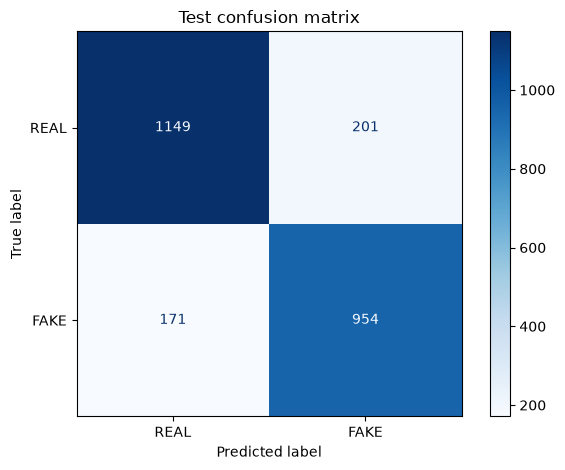

Confident verdicts (outside the UNCERTAIN band): 69% of test images, accuracy on those = 0.9310

=== Leave-one-source-out (what to expect on NEW data) ===
held-out openfake        [real+fake                  ] accuracy 0.545   AUC 0.580
held-out hemg_art        [real+fake                  ] accuracy 0.534   AUC 0.655
held-out coco_real       [real only (specificity)    ] accuracy 0.808   AUC nan
held-out local_sdturbo   [fake only (detection rate) ] accuracy 0.959   AUC nan

If held-out accuracy is far below the random-split accuracy, the model still depends on source-specific cues: add more diverse data (my_data/, more sources) rather than training longer.


In [8]:
pte = sigmoid(logit(scaler, head, X[te]) / TEMP)
print("=== Random test split (optimistic) ===")
print(f"accuracy {accuracy_score(y[te], pte > .5):.4f} | ROC-AUC {roc_auc_score(y[te], pte):.4f}")
print(classification_report(y[te], pte > .5, target_names=["REAL", "FAKE"], digits=4))
ConfusionMatrixDisplay(confusion_matrix(y[te], pte > .5), display_labels=["REAL", "FAKE"]).plot(cmap="Blues", values_format="d")
plt.title("Test confusion matrix"); plt.tight_layout(); plt.savefig(RESULTS/"confusion.png", dpi=130); plt.show()

conf = (pte >= BAND_FAKE) | (pte <= BAND_REAL)
print(f"Confident verdicts (outside the UNCERTAIN band): {conf.mean():.0%} of test images, "
      f"accuracy on those = {accuracy_score(y[te][conf], pte[conf] > .5):.4f}")

print("\n=== Leave-one-source-out (what to expect on NEW data) ===")
loso_rows = []
for held in [s for s in data if not s.startswith("my_data")]:
    m_te, m_tr = src == held, src != held
    if len(np.unique(y[m_tr])) < 2: continue
    sc_, lr_ = fit_head(X[m_tr], y[m_tr], BEST_C)
    p = sigmoid(logit(sc_, lr_, X[m_te]) / TEMP)
    acc = accuracy_score(y[m_te], p > .5)
    auc_s = roc_auc_score(y[m_te], p) if len(np.unique(y[m_te])) == 2 else float("nan")
    kind = "real+fake" if len(np.unique(y[m_te])) == 2 else ("fake only (detection rate)" if y[m_te][0] == 1 else "real only (specificity)")
    loso_rows.append((held, kind, acc, auc_s)); print(f"held-out {held:15s} [{kind:27s}] accuracy {acc:.3f}   AUC {auc_s:.3f}")
(RESULTS/"loso.json").write_text(json.dumps([dict(source=a, kind=b, acc=c, auc=None if np.isnan(d) else d) for a, b, c, d in loso_rows], indent=2))
print("\nIf held-out accuracy is far below the random-split accuracy, the model still depends on source-specific cues: "
      "add more diverse data (my_data/, more sources) rather than training longer.")

## 10. Save the detector (with SHA-256)

In [9]:
import joblib
bundle_path = MODELS / "detector_v3.joblib"
joblib.dump(dict(scaler=scaler, head=head, temperature=TEMP, backbone=BACKBONE, crop=CROP,
                 band_fake=BAND_FAKE, band_real=BAND_REAL, sources=list(data)), bundle_path)
def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()
print("Saved:", bundle_path, "\nSHA-256:", sha256_file(bundle_path))

Saved: c:\Users\Tankala Bhaskar teja\ISC_PROJECT-KOMAL\models_v3\detector_v3.joblib 
SHA-256: 1450ad0691c01290cb7e4a945a7f9fb8c26202575aa6521685367d1b82af6b03


## 11. Check your own images
Put image files in the `test_images/` folder (or edit `IMAGE_PATHS`; on Colab you can run the optional upload line). For each image the detector averages **10 views** (5 crops × flip) and reports a calibrated probability that the image is AI-generated:

* `P(AI) ≥ 0.80` → **LIKELY AI-GENERATED**
* `P(AI) ≤ 0.20` → **LIKELY REAL**
* otherwise → **UNCERTAIN** (treat as unknown — do not read it as "real")

`view_spread` shows how much the views disagree; a large value means a shaky result.

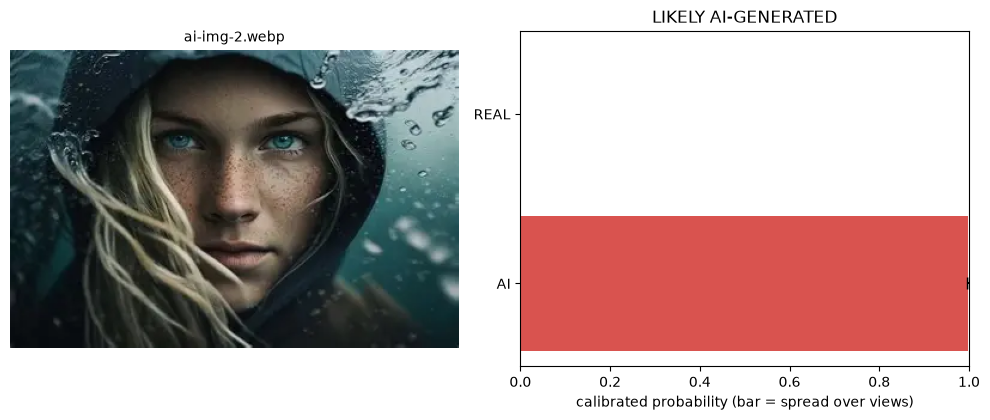

{
  "file": "ai-img-2.webp",
  "verdict": "LIKELY AI-GENERATED",
  "p_ai": 0.9975,
  "view_spread": 0.0019,
  "size": [
    375,
    249
  ],
  "sha256": "5ed2023dae860698c4441be32026613ad4342b8a84545fc30915a57a518b83d2"
}


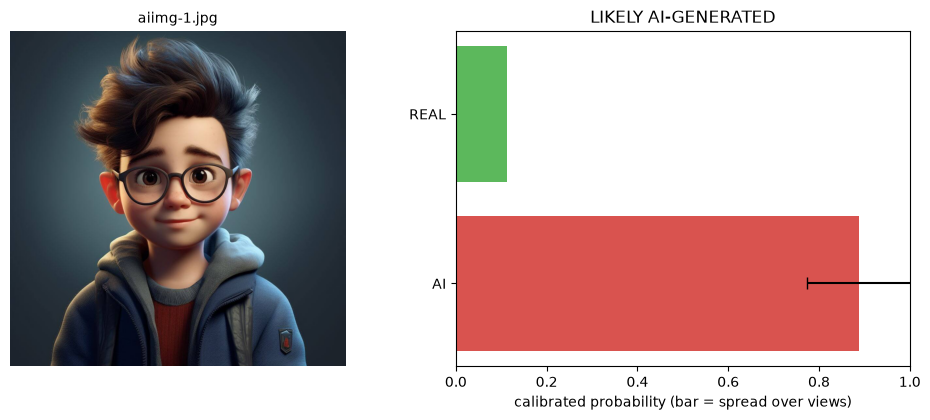

{
  "file": "aiimg-1.jpg",
  "verdict": "LIKELY AI-GENERATED",
  "p_ai": 0.8882,
  "view_spread": 0.1146,
  "size": [
    1024,
    1024
  ],
  "sha256": "4a539b832400718bebd505d6317fe4d33d8abee6f79577131bfd2d7bb92acc46"
}


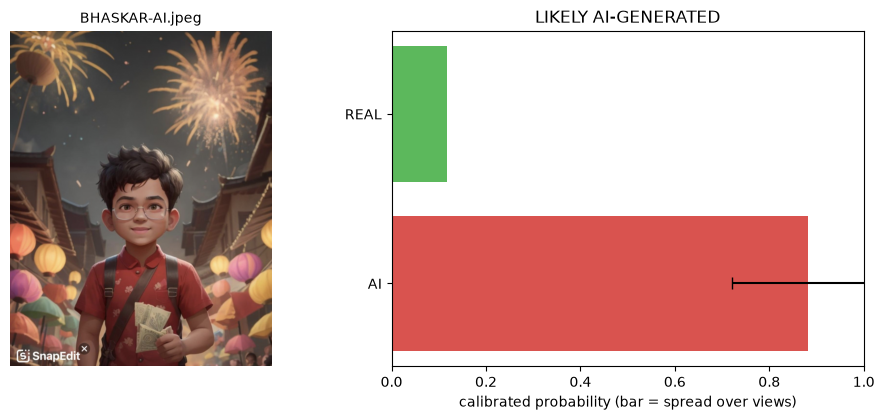

{
  "file": "BHASKAR-AI.jpeg",
  "verdict": "LIKELY AI-GENERATED",
  "p_ai": 0.8827,
  "view_spread": 0.1617,
  "size": [
    1076,
    1380
  ],
  "sha256": "f369ee40567aadd3321e03263f3d7cc56f925768929ceb7869b670be1208e789"
}


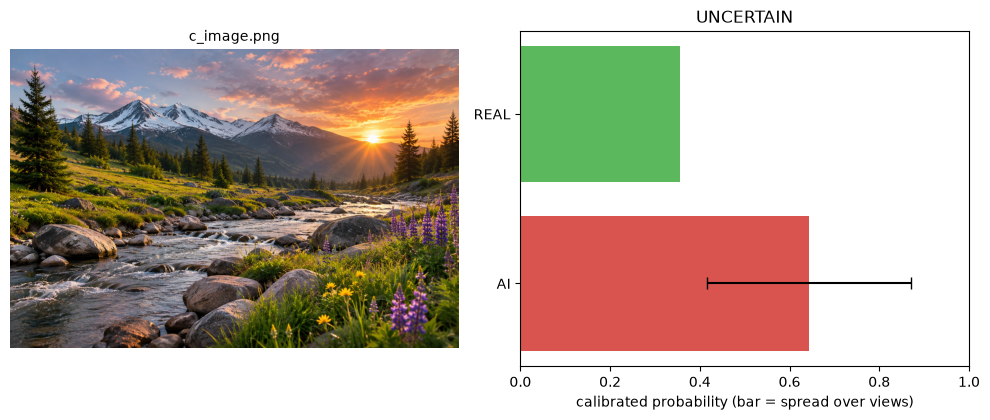

{
  "file": "c_image.png",
  "verdict": "UNCERTAIN",
  "p_ai": 0.6443,
  "view_spread": 0.2274,
  "size": [
    1536,
    1024
  ],
  "sha256": "46f854f7541eae31a132b969630fc0b71b233044c260b138341a2e15298af627"
}


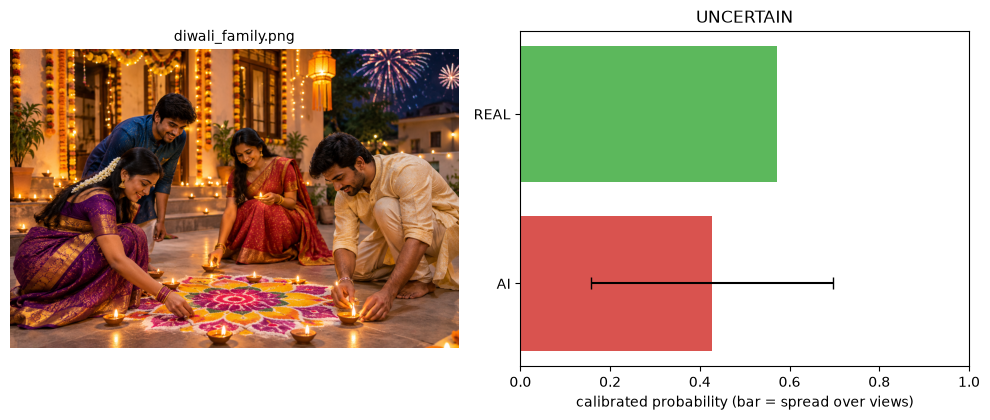

{
  "file": "diwali_family.png",
  "verdict": "UNCERTAIN",
  "p_ai": 0.4272,
  "view_spread": 0.2689,
  "size": [
    1536,
    1024
  ],
  "sha256": "0e78ee735695e009a1cd598acc54d85f97f445f263cce5925abad2e86a9f6359"
}


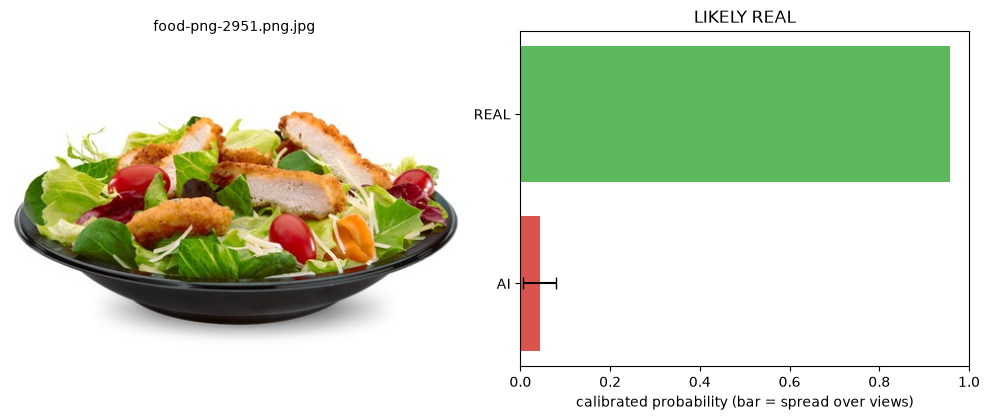

{
  "file": "food-png-2951.png.jpg",
  "verdict": "LIKELY REAL",
  "p_ai": 0.0429,
  "view_spread": 0.0366,
  "size": [
    443,
    315
  ],
  "sha256": "92ea5143e0cf5676ca6a3525748aa13595ff09af077e9316bb507216eefca072"
}


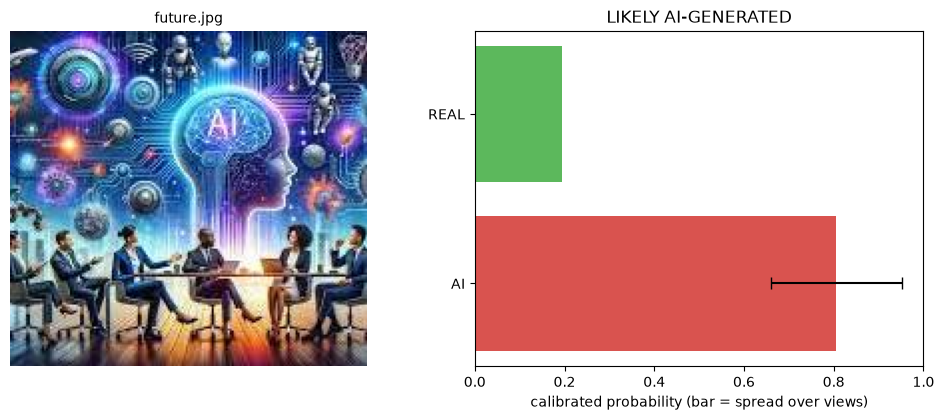

{
  "file": "future.jpg",
  "verdict": "LIKELY AI-GENERATED",
  "p_ai": 0.8063,
  "view_spread": 0.1457,
  "size": [
    179,
    168
  ],
  "sha256": "9fc660051312efa556c7a6c4fba990da25f140bbe307cff1534d4d9a76348f6b"
}


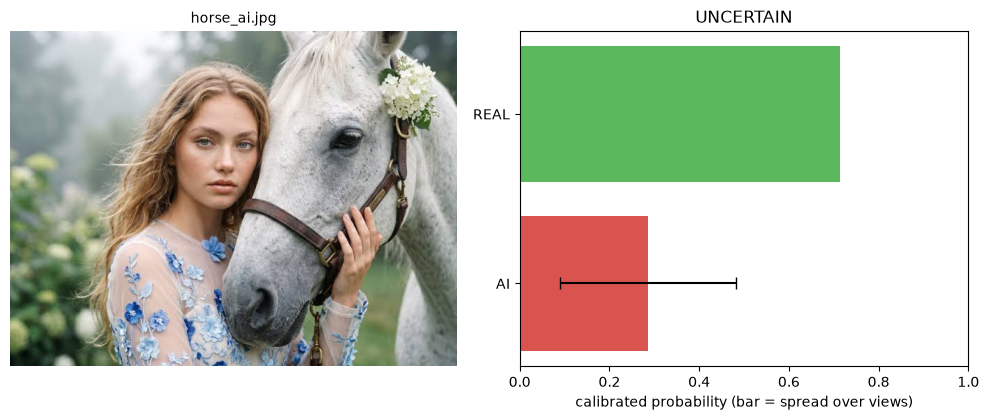

{
  "file": "horse_ai.jpg",
  "verdict": "UNCERTAIN",
  "p_ai": 0.286,
  "view_spread": 0.1971,
  "size": [
    640,
    480
  ],
  "sha256": "e6c00db1b11fd3f1750e14a05dd0685ea14e0c5046b145ac7e22df638b0dbad3"
}


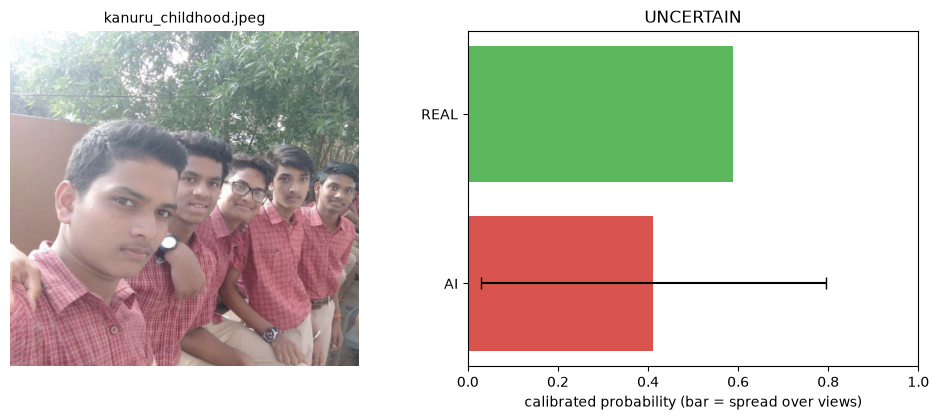

{
  "file": "kanuru_childhood.jpeg",
  "verdict": "UNCERTAIN",
  "p_ai": 0.4115,
  "view_spread": 0.3831,
  "size": [
    812,
    780
  ],
  "sha256": "8273540b9bf1dc4ca87dcf7c918fa719566500aa509000eace34f40820d35351"
}


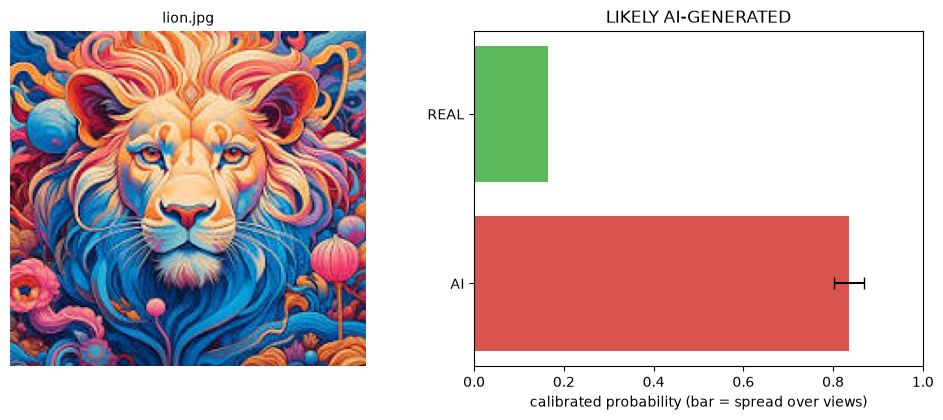

{
  "file": "lion.jpg",
  "verdict": "LIKELY AI-GENERATED",
  "p_ai": 0.8344,
  "view_spread": 0.0335,
  "size": [
    204,
    192
  ],
  "sha256": "bda8262053e98ad2b1ba74eabeb076af66b9b88901373a35c91ad460113979fa"
}


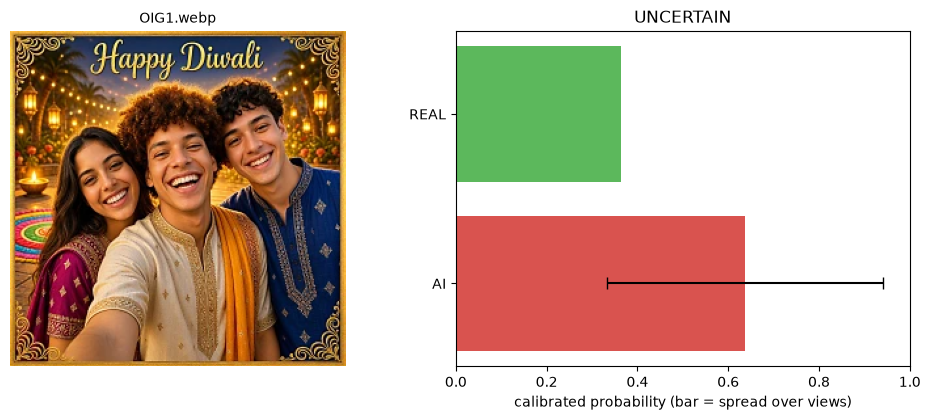

{
  "file": "OIG1.webp",
  "verdict": "UNCERTAIN",
  "p_ai": 0.636,
  "view_spread": 0.3039,
  "size": [
    256,
    256
  ],
  "sha256": "0b72f1b7830350521452788d5f282a0faddb5ddc117c3b176a508a5100f7a2c9"
}


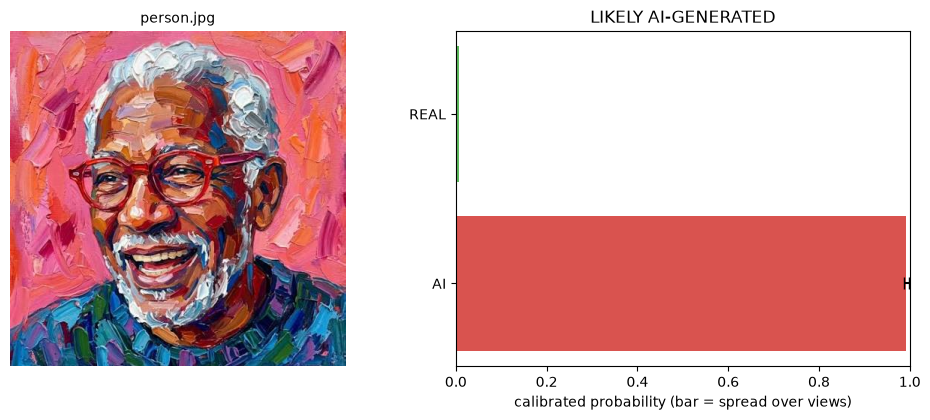

{
  "file": "person.jpg",
  "verdict": "LIKELY AI-GENERATED",
  "p_ai": 0.9924,
  "view_spread": 0.0051,
  "size": [
    447,
    447
  ],
  "sha256": "9ed5c53f1b85d5b7c98d1bb9716896cbbd2db3e8b35e9b154c44f478cf7747da"
}


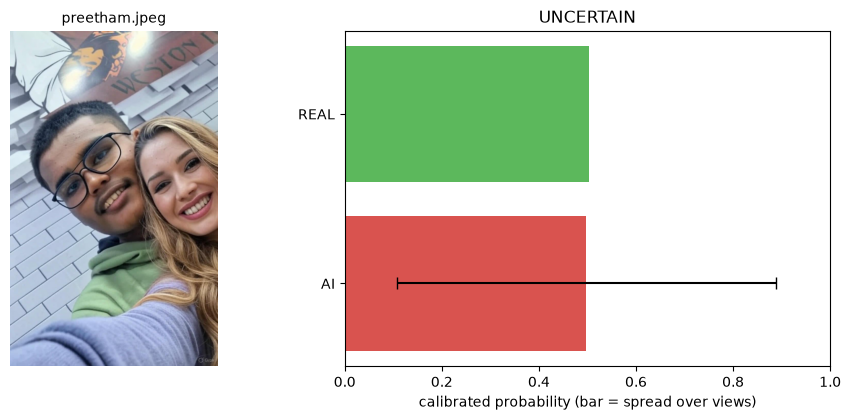

{
  "file": "preetham.jpeg",
  "verdict": "UNCERTAIN",
  "p_ai": 0.4974,
  "view_spread": 0.3903,
  "size": [
    815,
    1316
  ],
  "sha256": "0464db4f994516b4e47020e4084256949e78372365a781c7c0e6a29cc1673bbd"
}


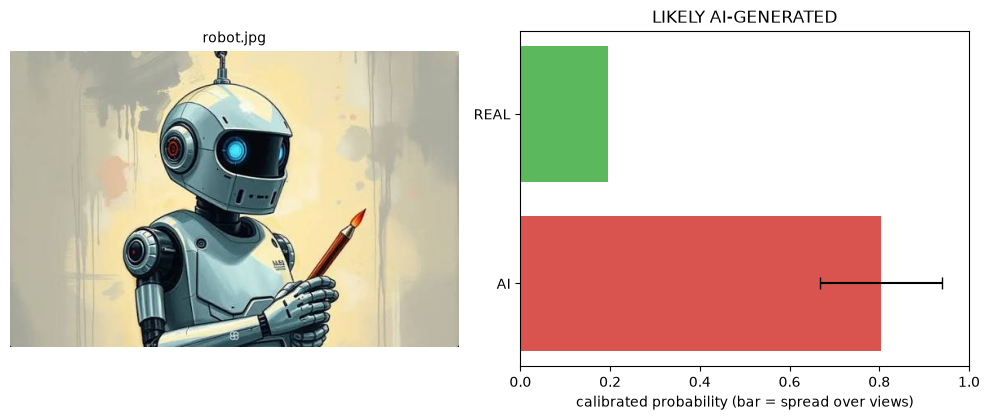

{
  "file": "robot.jpg",
  "verdict": "LIKELY AI-GENERATED",
  "p_ai": 0.8044,
  "view_spread": 0.1359,
  "size": [
    550,
    363
  ],
  "sha256": "c022e7e9ba46cddee05d252719964b6c092b4d2bfcbad3b30457a8e2edd6828a"
}


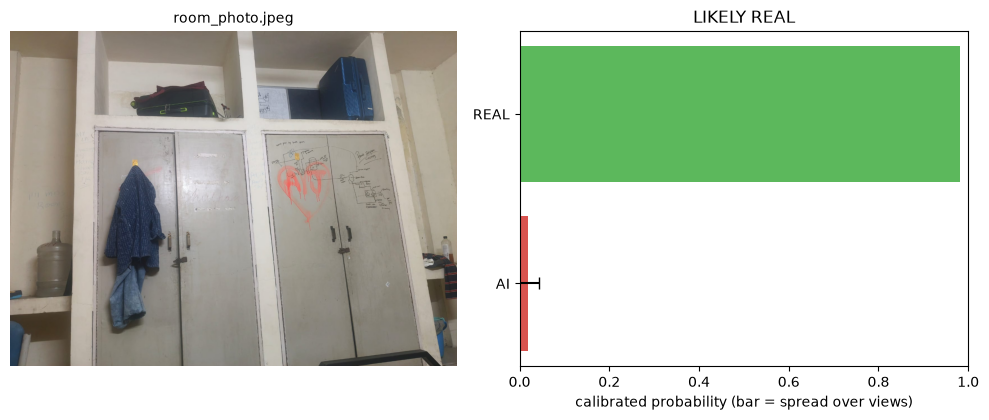

{
  "file": "room_photo.jpeg",
  "verdict": "LIKELY REAL",
  "p_ai": 0.0179,
  "view_spread": 0.0246,
  "size": [
    1599,
    1200
  ],
  "sha256": "9dc78ecb4228f8dbdf4e2345ba9b5944f28d35e27d7178505360ba582658bf12"
}


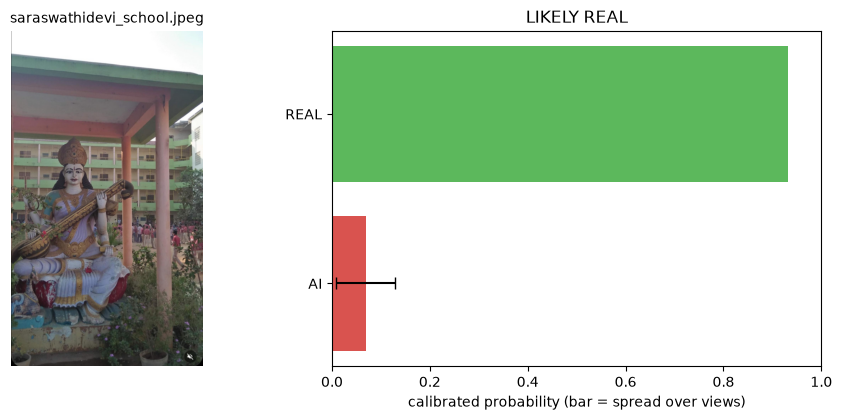

{
  "file": "saraswathidevi_school.jpeg",
  "verdict": "LIKELY REAL",
  "p_ai": 0.0687,
  "view_spread": 0.0606,
  "size": [
    1080,
    1888
  ],
  "sha256": "fb2bc8e5d379fdb7d2f818ce1cc1a83408f817e44bfad5fe1493d5ee2d0d560f"
}


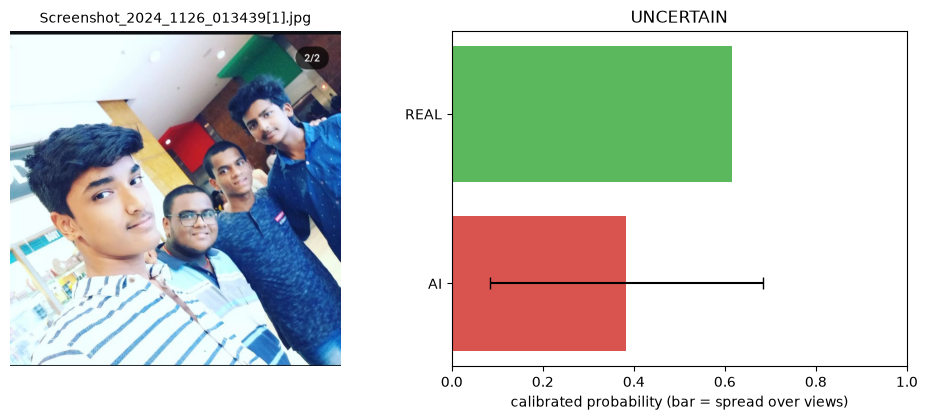

{
  "file": "Screenshot_2024_1126_013439[1].jpg",
  "verdict": "UNCERTAIN",
  "p_ai": 0.3839,
  "view_spread": 0.2994,
  "size": [
    706,
    716
  ],
  "sha256": "5140342c073c7fa5f0803bf6296ad697ff74f35610613239ec543fcf99de970a"
}


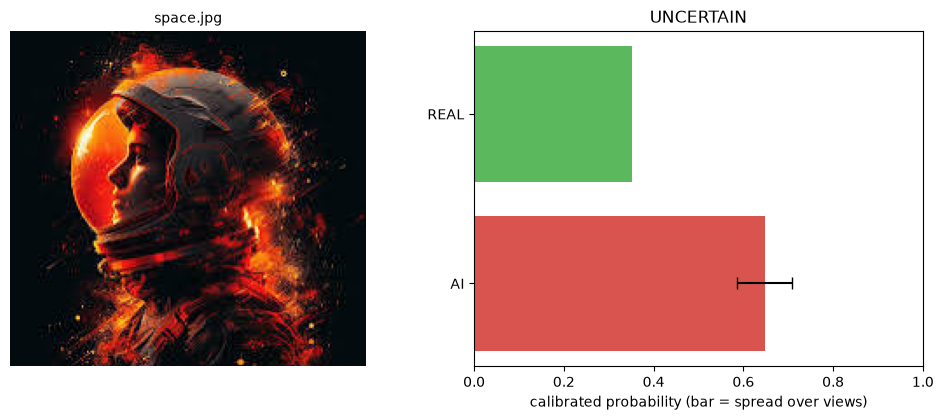

{
  "file": "space.jpg",
  "verdict": "UNCERTAIN",
  "p_ai": 0.6475,
  "view_spread": 0.0607,
  "size": [
    204,
    192
  ],
  "sha256": "9355ebf6deaa73cbf4d941255413377799a5820b3405867d0ddad931d6344664"
}


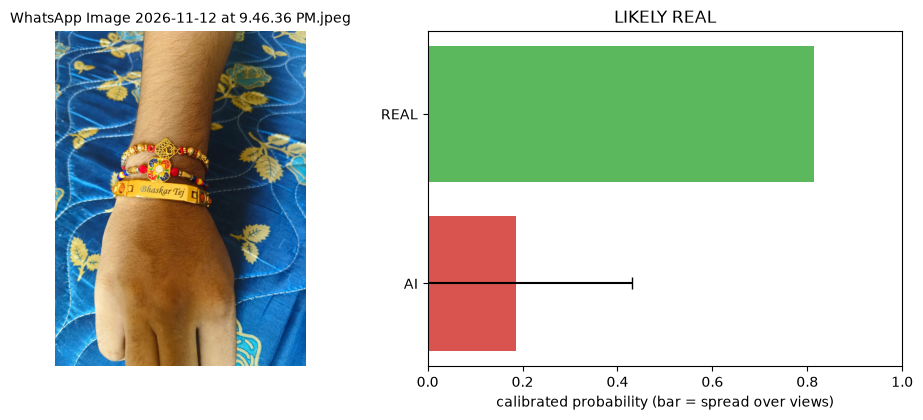

{
  "file": "WhatsApp Image 2026-11-12 at 9.46.36 PM.jpeg",
  "verdict": "LIKELY REAL",
  "p_ai": 0.1867,
  "view_spread": 0.2446,
  "size": [
    1200,
    1599
  ],
  "sha256": "01877b6964ce373ab6fb89a076da2af9743a1331529425774903f6cb58eade9c"
}


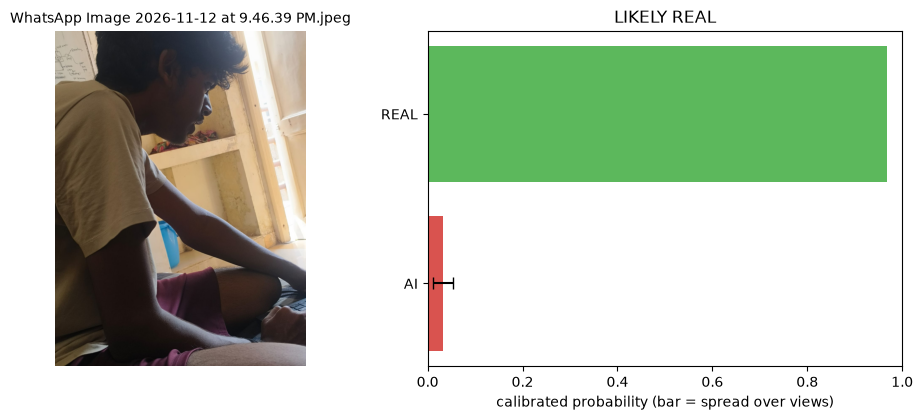

{
  "file": "WhatsApp Image 2026-11-12 at 9.46.39 PM.jpeg",
  "verdict": "LIKELY REAL",
  "p_ai": 0.0328,
  "view_spread": 0.0214,
  "size": [
    1200,
    1599
  ],
  "sha256": "c98d880d89777700f76feaeb842590e06ceff49ddc6fe9ef58cfb9103157eb24"
}


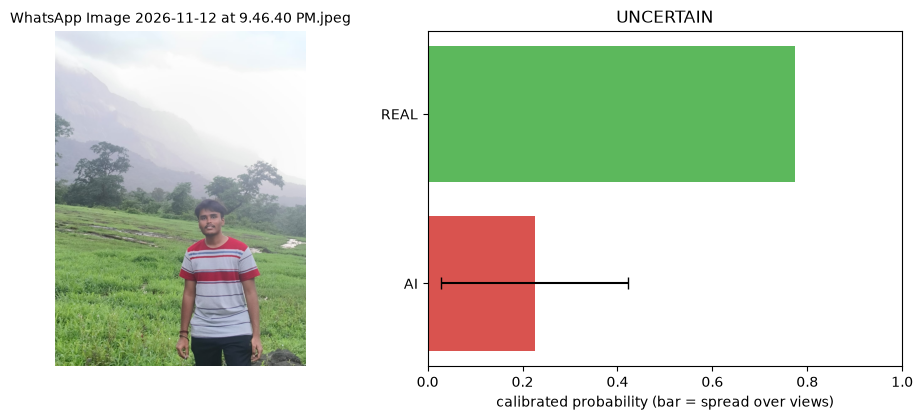

{
  "file": "WhatsApp Image 2026-11-12 at 9.46.40 PM.jpeg",
  "verdict": "UNCERTAIN",
  "p_ai": 0.2257,
  "view_spread": 0.197,
  "size": [
    1200,
    1599
  ],
  "sha256": "db65335b0f8d1814fabff0e9cc136fa8266d782a80295d22fc2e51bde9bcfa5b"
}


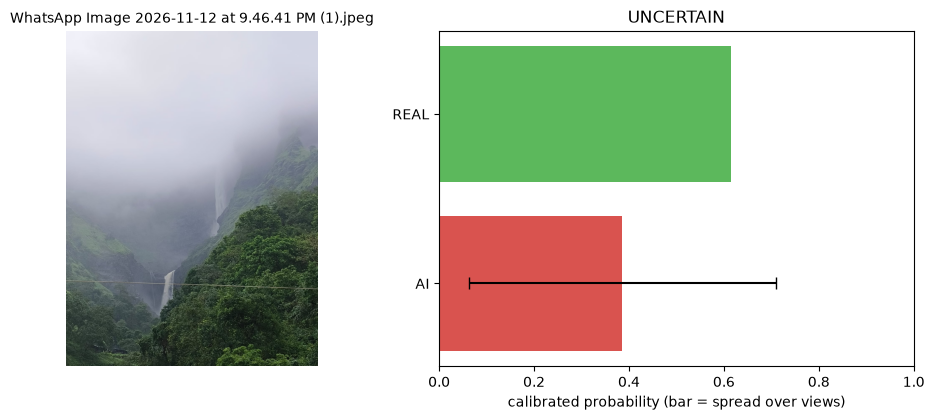

{
  "file": "WhatsApp Image 2026-11-12 at 9.46.41 PM (1).jpeg",
  "verdict": "UNCERTAIN",
  "p_ai": 0.3858,
  "view_spread": 0.3233,
  "size": [
    1200,
    1599
  ],
  "sha256": "e3de7c42990fe7dc3f36ee67a55699aa2655f77e00f1969ec6080b572b1cdd74"
}


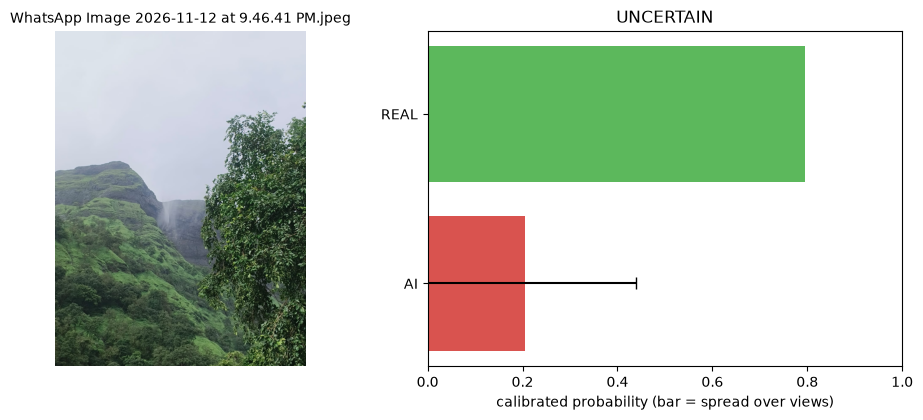

{
  "file": "WhatsApp Image 2026-11-12 at 9.46.41 PM.jpeg",
  "verdict": "UNCERTAIN",
  "p_ai": 0.2046,
  "view_spread": 0.2353,
  "size": [
    1200,
    1599
  ],
  "sha256": "dae9476a716f545134727444789150b8af1cbcbbbeafab4ffff956308a823f44"
}


In [10]:
# Optional on Colab: upload images into test_images/
try:
    from google.colab import files
    up = files.upload()
    for name, content in up.items(): (ROOT/"test_images"/name).write_bytes(content)
except Exception:
    pass

IMAGE_PATHS = sorted(p for p in (ROOT/"test_images").iterdir() if p.suffix.lower() in EXTS)
IMAGE_PATHS += [Path("BHASKAR-AI.jpeg")] if Path("BHASKAR-AI.jpeg").exists() else []

def analyze_image(path, show=True):
    path = Path(path)
    img = Image.open(path).convert("RGB")
    views = eval_views(img)
    z = logit(scaler, head, embed_many(list(views))) / TEMP
    pv = sigmoid(z); p_ai, spread = float(pv.mean()), float(pv.std())
    verdict = "LIKELY AI-GENERATED" if p_ai >= BAND_FAKE else "LIKELY REAL" if p_ai <= BAND_REAL else "UNCERTAIN"
    if verdict != "UNCERTAIN" and spread > 0.25: verdict = "UNCERTAIN"
    out = dict(file=path.name, verdict=verdict, p_ai=round(p_ai, 4), view_spread=round(spread, 4), size=img.size, sha256=sha256_file(path))
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(10, 4.3))
        ax[0].imshow(img); ax[0].axis("off"); ax[0].set_title(path.name, fontsize=10)
        ax[1].barh(["AI", "REAL"], [p_ai, 1 - p_ai], color=["#d9534f", "#5cb85c"]); ax[1].errorbar([p_ai], [0], xerr=[spread], color="k", capsize=4)
        ax[1].set_xlim(0, 1); ax[1].set_title(verdict); ax[1].set_xlabel("calibrated probability (bar = spread over views)")
        plt.tight_layout(); plt.show()
    print(json.dumps(out, indent=2)); return out

results = [analyze_image(p) for p in IMAGE_PATHS] if IMAGE_PATHS else print("No images found — add some to test_images/")

## 12. If an image is still wrong — the fix loop
1. Copy the wrongly-classified image into `my_data/fake/` (if it is AI) or `my_data/real/` (if it is real). Add 10–50 similar ones if you can; the more varied, the better.
2. Optionally raise `N_LOCAL_FAKES` (cell 2) or add prompts in cell 6 that match your problem style, then run cell 6 again.
3. Re-run cells 7 → 11. Cached sources are reused, so only the new images are processed (seconds).

**Reading the results honestly**
* Good leave-one-source-out numbers (≳ 0.85–0.90) mean it should handle new data of those kinds.
* A hand-drawn cartoon by a human and an AI cartoon can look alike to *any* detector — expect `UNCERTAIN` there. That is the correct output, not a failure.
* For news/media verification, combine this with **provenance** (C2PA content credentials, original-source checks). A pixel-based detector alone should never be the final authority.